# Практика №2. Рекуррентная нейронная сеть (RNN / LSTM)

Задача: определить тональность отзыва о фильме - отрицательную или положительную - по последовательности слов.

Датасет: Large Movie Review Dataset (IMDB), 50 000 размеченных отзывов: 25 000 для исходного обучения и 25 000 в официальной тестовой части. Встроенный загрузчик Keras возвращает отзывы в виде последовательностей целочисленных индексов слов. Источник: [Keras - IMDB dataset](https://keras.io/api/datasets/imdb/); исходный набор создан для исследования анализа тональности отзывов.

Рекуррентная сеть обрабатывает последовательность по шагам и передаёт скрытое состояние между ними. В этой работе применяется LSTM - разновидность RNN с механизмами управления памятью, помогающими учитывать контекст последовательности.

Для сохранения независимой проверки исходная тестовая часть IMDB остаётся нетронутой. Исходные 25 000 обучающих отзывов дополнительно делятся на train и validation.

In [1]:
%pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

## 1. Загрузка данных

Используем встроенный загрузчик IMDB. Параметр num_words ограничивает словарь наиболее частотными словами. Более редкие слова заменяются специальным индексом неизвестного слова. Длины исходных последовательностей пока не ограничиваем: это позволит самостоятельно оценить распределение длины отзывов перед дополнением и обрезкой.

In [3]:
MAX_FEATURES = 10_000
MAX_LENGTH = 250

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.imdb.load_data(
    num_words=MAX_FEATURES
)

y_train_raw = np.asarray(y_train_raw, dtype=np.int32)
y_test_raw = np.asarray(y_test_raw, dtype=np.int32)

print(f"Исходная train-часть: {len(x_train_raw)} отзывов")
print(f"Официальная test-часть: {len(x_test_raw)} отзывов")
print("Пример последовательности (первые 25 токенов):", x_train_raw[0][:25])
print("Метки классов:", np.unique(np.concatenate([y_train_raw, y_test_raw])))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Исходная train-часть: 25000 отзывов
Официальная test-часть: 25000 отзывов
Пример последовательности (первые 25 токенов): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50]
Метки классов: [0 1]


## 2. Проверка качества данных

Проверяем пустые последовательности, недопустимые метки, нецелочисленные и выходящие за словарь токены, точные дубликаты и совпадения между исходными train/test. Внутри каждой части точные дубликаты удаляются. Если одна и та же последовательность обнаруживается в обеих частях, экземпляр из train удаляется, чтобы не допустить пересечения обучающих и тестовых данных. Противоречивые дубликаты с разными метками исключаются из соответствующей части.

In [4]:
def clean_review_split(sequences, labels, vocab_size):
    valid_indices = []
    invalid_count = 0
    for index, (sequence, label) in enumerate(zip(sequences, labels)):
        sequence_array = np.asarray(sequence)
        is_valid = (
            len(sequence_array) > 0
            and int(label) in (0, 1)
            and np.issubdtype(sequence_array.dtype, np.integer)
            and np.all(sequence_array >= 0)
            and np.all(sequence_array < vocab_size)
        )
        if is_valid:
            valid_indices.append(index)
        else:
            invalid_count += 1

    first_by_key = {}
    conflicting_keys = set()
    duplicate_count = 0
    for index in valid_indices:
        key = tuple(int(token) for token in sequences[index])
        label = int(labels[index])
        if key in first_by_key:
            duplicate_count += 1
            if first_by_key[key][1] != label:
                conflicting_keys.add(key)
        else:
            first_by_key[key] = (index, label)

    keep_indices = [
        index for key, (index, _) in first_by_key.items()
        if key not in conflicting_keys
    ]
    cleaned_sequences = [sequences[index] for index in keep_indices]
    cleaned_labels = labels[keep_indices]
    return cleaned_sequences, cleaned_labels, invalid_count, duplicate_count, len(conflicting_keys)

x_train_clean, y_train_clean, train_invalid, train_duplicates, train_conflicts = clean_review_split(
    x_train_raw, y_train_raw, MAX_FEATURES
)
x_test_clean, y_test_clean, test_invalid, test_duplicates, test_conflicts = clean_review_split(
    x_test_raw, y_test_raw, MAX_FEATURES
)

test_keys = {tuple(int(token) for token in sequence) for sequence in x_test_clean}
train_keep = [
    index for index, sequence in enumerate(x_train_clean)
    if tuple(int(token) for token in sequence) not in test_keys
]
cross_split_duplicates = len(x_train_clean) - len(train_keep)
x_train_clean = [x_train_clean[index] for index in train_keep]
y_train_clean = y_train_clean[train_keep]

print("Удалено некорректных train-последовательностей:", train_invalid)
print("Удалено точных дубликатов train:", train_duplicates)
print("Удалено конфликтующих train-последовательностей:", train_conflicts)
print("Удалено некорректных test-последовательностей:", test_invalid)
print("Удалено точных дубликатов test:", test_duplicates)
print("Удалено конфликтующих test-последовательностей:", test_conflicts)
print("Совпадений между исходными train/test удалено из train:", cross_split_duplicates)
print("Итоговые размеры:", len(x_train_clean), "train и", len(x_test_clean), "test")

Удалено некорректных train-последовательностей: 0
Удалено точных дубликатов train: 99
Удалено конфликтующих train-последовательностей: 0
Удалено некорректных test-последовательностей: 0
Удалено точных дубликатов test: 199
Удалено конфликтующих test-последовательностей: 0
Совпадений между исходными train/test удалено из train: 123
Итоговые размеры: 24778 train и 24801 test


## 3. Разведочный анализ данных (EDA)

Исследуем баланс классов и длины последовательностей. Для наглядности декодируем один отзыв с помощью обратного словаря IMDB. Корреляционная матрица строится по числовым характеристикам последовательностей: длина, число уникальных токенов, доля уникальных токенов и количество повторов. Эти показатели описывают структуру последовательности, а не смысловую близость слов.

Описательная статистика длины и структуры отзывов:


,count,mean,std,min,25%,50%,75%,max
sequence_length,24778.0,238.931552,176.615744,11.000000,130.000000,178.000000,291.00000,2494.0
unique_tokens,24778.0,131.782388,71.584377,10.000000,85.000000,110.000000,160.00000,588.0
unique_token_ratio,24778.0,0.608026,0.096339,0.146154,0.543986,0.609023,0.66875,1.0
repeated_tokens,24778.0,107.149165,107.257417,0.000000,44.000000,69.000000,130.00000,1973.0
sentiment,24778.0,0.502099,0.500006,0.000000,0.000000,1.000000,1.00000,1.0


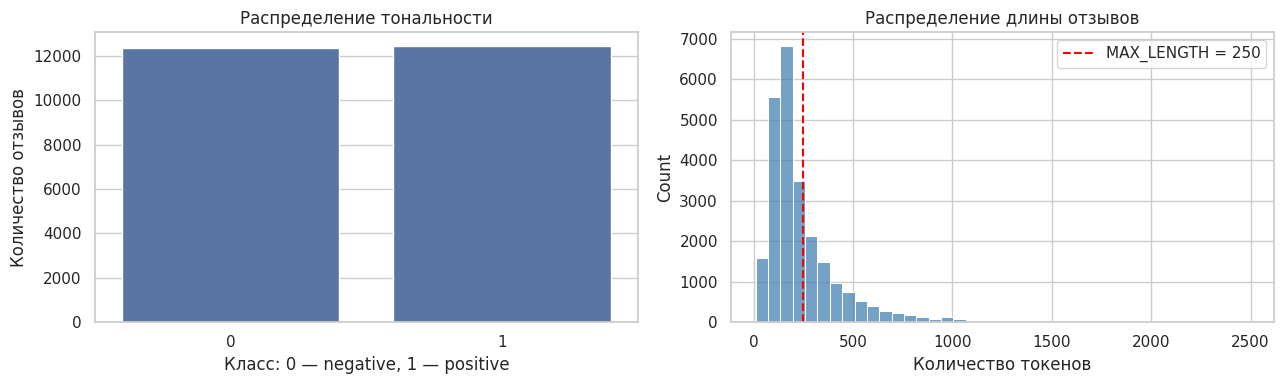

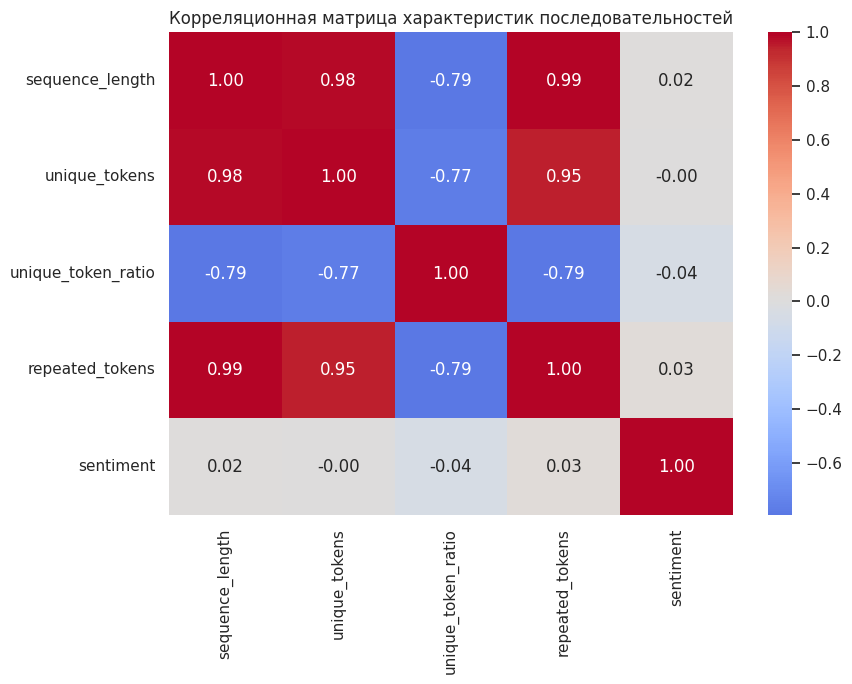

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Пример декодированного отзыва:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was


In [5]:
train_lengths = np.array([len(sequence) for sequence in x_train_clean])
train_unique_counts = np.array([len(set(sequence)) for sequence in x_train_clean])
train_unique_ratio = train_unique_counts / np.maximum(train_lengths, 1)
train_repeated_counts = train_lengths - train_unique_counts

eda_df = pd.DataFrame({
    "sequence_length": train_lengths,
    "unique_tokens": train_unique_counts,
    "unique_token_ratio": train_unique_ratio,
    "repeated_tokens": train_repeated_counts,
    "sentiment": y_train_clean,
})

print("Описательная статистика длины и структуры отзывов:")
display(eda_df.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y_train_clean, ax=axes[0])
axes[0].set_title("Распределение тональности")
axes[0].set_xlabel("Класс: 0 — negative, 1 — positive")
axes[0].set_ylabel("Количество отзывов")
sns.histplot(train_lengths, bins=40, ax=axes[1], color="steelblue")
axes[1].axvline(MAX_LENGTH, color="red", linestyle="--", label=f"MAX_LENGTH = {MAX_LENGTH}")
axes[1].set_title("Распределение длины отзывов")
axes[1].set_xlabel("Количество токенов")
axes[1].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(eda_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица характеристик последовательностей")
plt.tight_layout()
plt.show()

word_index = tf.keras.datasets.imdb.get_word_index()
reverse_word_index = {index + 3: word for word, index in word_index.items()}
reverse_word_index.update({0: "<PAD>", 1: "<START>", 2: "<UNK>"})

def decode_review(sequence, limit=100):
    return " ".join(reverse_word_index.get(int(token), "<UNK>") for token in sequence[:limit])

print("Пример декодированного отзыва:")
print(decode_review(x_train_clean[0], limit=100))

## 4. Подготовка последовательностей и разделение выборки

Все отзывы приводятся к одинаковой длине MAX_LENGTH = 250: короткие дополняются нулями, длинные обрезаются. Используется padding="post" и truncating="post". Исходная официальная тестовая часть IMDB остаётся нетронутой. Обучающая часть делится на train и validation в пропорции 85/15 с сохранением долей классов.

In [6]:
X_train_all = tf.keras.utils.pad_sequences(
    x_train_clean, maxlen=MAX_LENGTH, padding="post", truncating="post", value=0
)
X_test = tf.keras.utils.pad_sequences(
    x_test_clean, maxlen=MAX_LENGTH, padding="post", truncating="post", value=0
)
y_train_all = y_train_clean.astype("int32")
y_test = y_test_clean.astype("int32")

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y_train_all,
)

print(f"Train: {len(X_train)} отзывов")
print(f"Validation: {len(X_val)} отзывов")
print(f"Test: {len(X_test)} отзывов (официальная тестовая часть IMDB)")
print("Форма одной последовательности:", X_train.shape[1])

Train: 21061 отзывов
Validation: 3717 отзывов
Test: 24801 отзывов (официальная тестовая часть IMDB)
Форма одной последовательности: 250


## 5. Проектирование рекуррентной нейронной сети LSTM

Слой Embedding преобразует целочисленные индексы слов в обучаемые плотные векторы. mask_zero=True сообщает сети, что нулевые значения добавлены только для выравнивания длины. Слой LSTM последовательно обрабатывает векторы и сохраняет информацию о контексте. После него расположены полносвязный слой, Dropout и выходной нейрон с сигмоидой для бинарной классификации.

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_LENGTH,)),
    tf.keras.layers.Embedding(
        input_dim=MAX_FEATURES,
        output_dim=64,
        mask_zero=True,
    ),
    tf.keras.layers.LSTM(64, dropout=0.20),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Обучение LSTM

Модель обучается по размеченным отзывам train, а validation используется для контроля переобучения. Применяется EarlyStopping по val_loss. Из-за рекуррентной обработки последовательностей обучение может занимать больше времени, чем у полносвязной модели; при необходимости можно временно уменьшить MAX_FEATURES, MAX_LENGTH или число эпох, сохранив параметры изменений в выводах.

Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 85s 492ms/step - accuracy: 0.7315 - auc: 0.8152 - loss: 0.5284 - precision: 0.7233 - recall: 0.7536 - val_accuracy: 0.8432 - val_auc: 0.9216 - val_loss: 0.3630 - val_precision: 0.8288 - val_recall: 0.8666
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 78s 471ms/step - accuracy: 0.8815 - auc: 0.9418 - loss: 0.3051 - precision: 0.8821 - recall: 0.8819 - val_accuracy: 0.8596 - val_auc: 0.9359 - val_loss: 0.3362 - val_precision: 0.8323 - val_recall: 0.9019
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 83s 474ms/step - accuracy: 0.8973 - auc: 0.9537 - loss: 0.2708 - precision: 0.8955 - recall: 0.9006 - val_accuracy: 0.8714 - val_auc: 0.9394 - val_loss: 0.3410 - val_precision: 0.8868 - val_recall: 0.8526
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 79s 458ms/step - accuracy: 0.9159 - auc: 0.9658 - loss: 0.2306 - precision: 0.9145 - recall: 0.9184 - val_accuracy: 0.8687 - val_auc: 0.9365 - val_loss: 0.3822 - val_precision: 0.8469 - val_recall: 0.9014
Epoch 5/10
165/165 ━

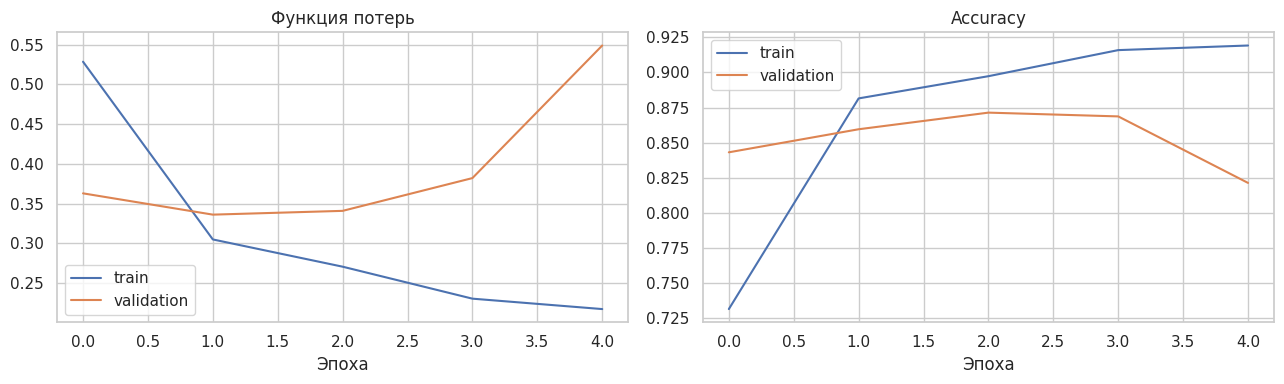

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1,
)

history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["loss"], label="train")
axes[0].plot(history_df["val_loss"], label="validation")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[1].plot(history_df["accuracy"], label="train")
axes[1].plot(history_df["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Итоговая оценка на тестовой выборке

После обучения оцениваем модель на официальных тестовых отзывах. Помимо Accuracy рассчитываются Balanced Accuracy, Precision, Recall, F1 и ROC-AUC. Матрица ошибок показывает, сколько отрицательных и положительных отзывов модель распознала правильно и сколько перепутала.

Итоговые метрики на тестовой выборке:


,value
Accuracy,0.855248
Balanced Accuracy,0.855107
Precision,0.827099
Recall,0.899437
F1,0.861753
ROC-AUC,0.927555



Отчёт по классам:
              precision    recall  f1-score   support

    negative       0.89      0.81      0.85     12361
    positive       0.83      0.90      0.86     12440

    accuracy                           0.86     24801
   macro avg       0.86      0.86      0.85     24801
weighted avg       0.86      0.86      0.85     24801



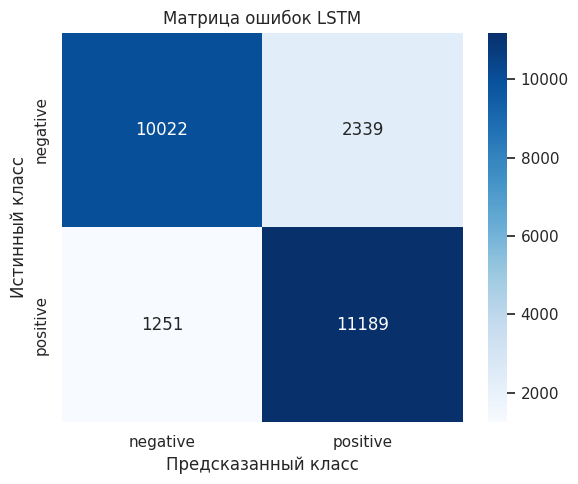

In [9]:
y_test_probability = model.predict(X_test, batch_size=256, verbose=0).ravel()
y_test_pred = (y_test_probability >= 0.5).astype(int)

test_metrics = {
    "Accuracy": float(accuracy_score(y_test, y_test_pred)),
    "Balanced Accuracy": float(balanced_accuracy_score(y_test, y_test_pred)),
    "Precision": float(precision_score(y_test, y_test_pred, zero_division=0)),
    "Recall": float(recall_score(y_test, y_test_pred, zero_division=0)),
    "F1": float(f1_score(y_test, y_test_pred, zero_division=0)),
    "ROC-AUC": float(roc_auc_score(y_test, y_test_probability)),
}

print("Итоговые метрики на тестовой выборке:")
display(pd.Series(test_metrics, name="value").to_frame())
print("\nОтчёт по классам:")
print(classification_report(y_test, y_test_pred, target_names=["negative", "positive"], zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.title("Матрица ошибок LSTM")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.show()

## 8. Примеры предсказаний и сохранение модели

Покажем несколько отзывов, их истинную тональность и предсказание сети. Сохраним модель, словарь IMDB и метрики. Сохранённый словарь необходим для сопоставления слов с теми же индексами при последующей подготовке новых текстов.

In [10]:
for index in range(3):
    actual = "positive" if y_test[index] == 1 else "negative"
    predicted = "positive" if y_test_pred[index] == 1 else "negative"
    print(f"Отзыв {index + 1}: факт={actual}, прогноз={predicted}, P(positive)={y_test_probability[index]:.3f}")
    print(decode_review(x_test_clean[index], limit=60))
    print("-" * 90)

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)
model.save(artifact_dir / "rnn_lstm_imdb.keras")

with (artifact_dir / "imdb_word_index.json").open("w", encoding="utf-8") as file:
    json.dump(word_index, file, ensure_ascii=False)

with (artifact_dir / "rnn_lstm_imdb_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        {
            "test_metrics": test_metrics,
            "max_features": MAX_FEATURES,
            "max_length": MAX_LENGTH,
            "class_names": ["negative", "positive"],
            "random_state": RANDOM_STATE,
        },
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Модель, словарь и метрики сохранены в папку artifacts/")

Отзыв 1: факт=negative, прогноз=negative, P(positive)=0.088
<START> please give this one a miss br br <UNK> <UNK> and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could have allowed this one on his plate he almost seemed to know this wasn't going to work out and his performance was quite <UNK> so
------------------------------------------------------------------------------------------
Отзыв 2: факт=positive, прогноз=positive, P(positive)=0.927
<START> this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the scenes take place on the same set in frances <UNK> the sandy dennis character apartment but the film builds to a disturbing climax br br the characters create an atmosphere <UNK> with sexual tension and
------------------------------------------------------------------------------------------
Отзыв 3: факт=positive, прогноз=positive, P(po